**Import Libraries**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor,RandomForestClassifier
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,f1_score,precision_score,recall_score,accuracy_score
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier

Data Loading

In [ ]:
df=pd.read_csv('/content/CORRECTED_2023_2026_NEPAL_FLOOD_WEATHER_KAGGLE.csv')
df.head()

,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,rain_mm,temperature_mean_c,dew_point_mean_c,precipitation_hours,relative_humidity_mean_pct,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,river_discharge_m3s
0,2023-01-01 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.315,0.0,12.2,-2.6,0,37,13.9,68.0,187,0.22
1,2023-01-02 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.315,0.0,11.1,-4.8,0,34,13.4,69.8,191,0.21
2,2023-01-03 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,11.5,-10.3,0,22,14.5,72.0,183,0.21
3,2023-01-04 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,9.6,-8.9,0,29,11.2,67.7,187,0.20
4,2023-01-05 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,10.1,-10.2,0,26,7.4,69.8,54,0.20


In [ ]:
df.tail()

,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,rain_mm,temperature_mean_c,dew_point_mean_c,precipitation_hours,relative_humidity_mean_pct,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,river_discharge_m3s
13385,2026-08-31 00:00:00,Chisapani,Karnali,Karnali,280.00,28.653056,81.286944,2215,16.3,0.392,16.3,28.3,26.2,21,89,7.1,27.7,90,2.22
13386,2026-08-31 00:00:00,Devghat,Narayani,Narayani/Gandak,450.00,27.710000,84.430000,603,42.8,0.361,42.8,28.3,26.5,22,91,9.1,24.8,89,4.43
13387,2026-08-31 00:00:00,Khokana,Bagmati,Bagmati,550.05,27.632222,85.293333,1315,29.8,0.412,29.8,23.4,21.8,17,92,6.9,20.9,317,4.09
13388,2026-08-31 00:00:00,Kusum,West Rapti,Rapti,375.00,28.007500,82.093889,230,20.3,0.419,20.3,27.7,26.3,18,93,9.6,28.8,87,621.30
13389,2026-08-31 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,5.5,0.411,5.5,23.9,20.6,18,82,4.4,33.5,246,3.60


In [ ]:
df.shape

(13390, 19)

Data Understanding

In [ ]:
#1. Identify the target variable for the prediction.

target='river_discharge_m3s'

In [ ]:
#2. Identify the numerical and categorical variables.
num_cols=df.select_dtypes(include=np.number).columns.tolist()
cat_cols=df.select_dtypes(exclude=np.number).columns.tolist()

print(num_cols)
print(cat_cols)

['dhm_station', 'latitude', 'longitude', 'elevation_m', 'precipitation_mm', 'soil_moisture_0_100cm_m3m3', 'rain_mm', 'temperature_mean_c', 'dew_point_mean_c', 'precipitation_hours', 'relative_humidity_mean_pct', 'wind_speed_max_kmh', 'wind_gusts_max_kmh', 'wind_direction_dominant_deg', 'river_discharge_m3s']
['date', 'location', 'river', 'basin']


In [ ]:
#3. Check the dataset for missing values and duplicate records.



In [ ]:
df.isna().sum()

,0
date,0
location,0
river,0
basin,0
dhm_station,0
latitude,0
longitude,0
elevation_m,0
precipitation_mm,0
soil_moisture_0_100cm_m3m3,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13390 entries, 0 to 13389
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   date                         13390 non-null  object 
 1   location                     13390 non-null  object 
 2   river                        13390 non-null  object 
 3   basin                        13390 non-null  object 
 4   dhm_station                  13390 non-null  float64
 5   latitude                     13390 non-null  float64
 6   longitude                    13390 non-null  float64
 7   elevation_m                  13390 non-null  int64  
 8   precipitation_mm             13390 non-null  float64
 9   soil_moisture_0_100cm_m3m3   13390 non-null  float64
 10  rain_mm                      13390 non-null  float64
 11  temperature_mean_c           13390 non-null  float64
 12  dew_point_mean_c             13390 non-null  float64
 13  precipitation_ho

In [ ]:
df['date']=pd.to_datetime(df['date'])

In [ ]:
df.dtypes

,0
date,datetime64[ns]
location,object
river,object
basin,object
dhm_station,float64
latitude,float64
longitude,float64
elevation_m,int64
precipitation_mm,float64
soil_moisture_0_100cm_m3m3,float64


In [ ]:
df.duplicated(subset=["date", "location"]).sum()

np.int64(0)

In [ ]:
#4. Analyze the distribution of the river discharge variable.

In [ ]:
df['river_discharge_m3s'].describe()

,river_discharge_m3s
count,13390.000000
mean,20.372064
std,84.333629
min,0.000000
25%,0.260000
50%,1.880000
75%,10.530000
max,3175.870000


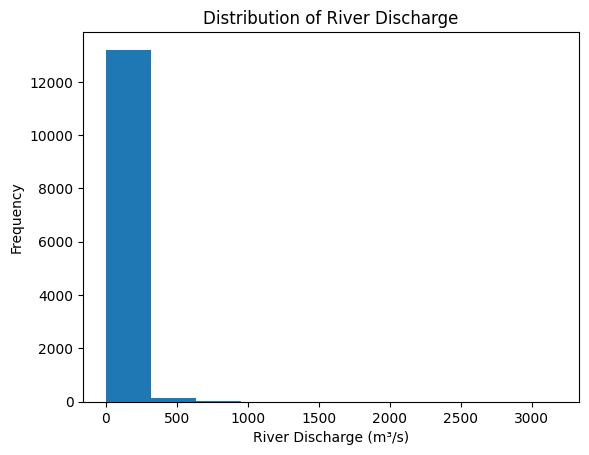

In [ ]:

plt.hist(df['river_discharge_m3s'], bins=10)
plt.xlabel('River Discharge (m³/s)')
plt.ylabel('Frequency')
plt.title('Distribution of River Discharge')
plt.show()

In [ ]:
#Identify the river station/location with the highest average river discharge.

In [ ]:
avg_discharge=df.groupby('location')['river_discharge_m3s'].mean().sort_values(ascending=False)
avg_discharge

,river_discharge_m3s
location,
Kusum,125.812158
Belsot,33.032636
Chameliya/Nayalbadi,31.393465
Bahrabise,5.051314
Devghat,2.331277
Khokana,1.658006
Chatara,1.491344
Rasuwagadhi,1.406751
Chisapani,0.847072


**Exploratory Data Analysis**

In [ ]:
#6. Analyze the relationship between rainfall/precipitation and river discharge.

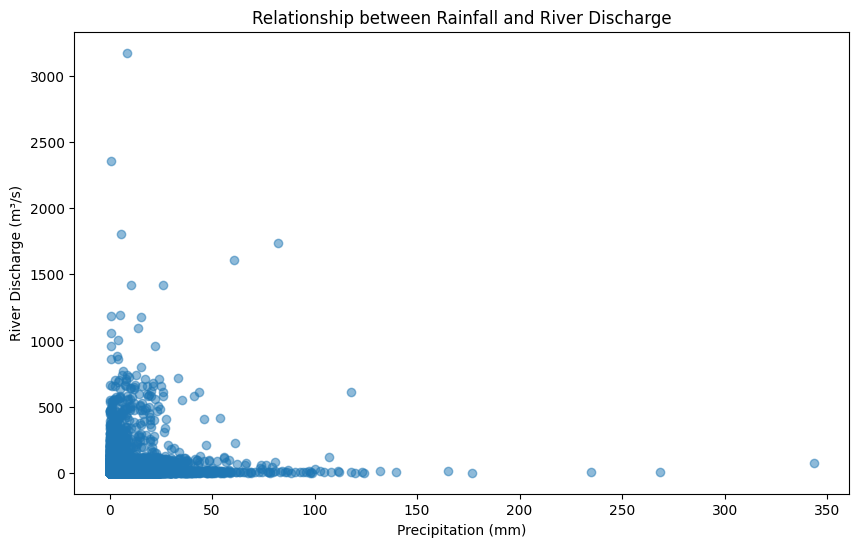

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(df['precipitation_mm'], df['river_discharge_m3s'], alpha=0.5)
plt.xlabel("Precipitation (mm)")
plt.ylabel('River Discharge (m³/s)')
plt.title('Relationship between Rainfall and River Discharge')

plt.show()

In [ ]:
#7. Identify which weather variable has the strongest relationship with river discharge.

In [ ]:
weather_cols=["precipitation_mm", "rain_mm", "soil_moisture_0_100cm_m3m3", "temperature_mean_c",
                "dew_point_mean_c", "precipitation_hours", "relative_humidity_mean_pct",
                "wind_speed_max_kmh", "wind_gusts_max_kmh", "wind_direction_dominant_deg"]

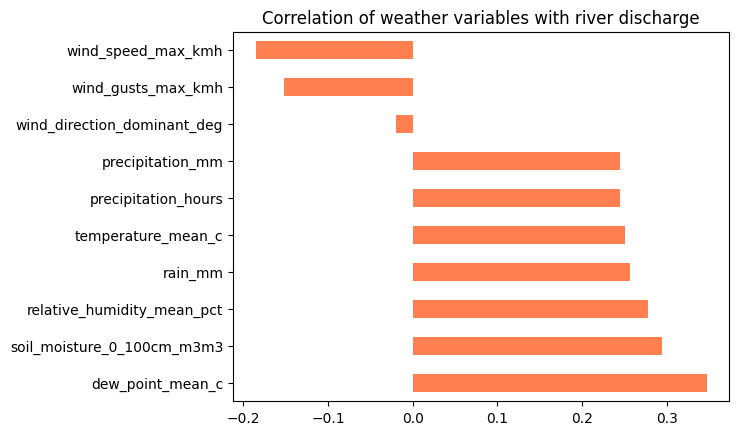

In [ ]:
corr = df[weather_cols + ["river_discharge_m3s"]].corr(method="spearman")["river_discharge_m3s"].drop("river_discharge_m3s")
corr = corr.sort_values(ascending=False)
corr.plot(kind="barh", color="coral", title="Correlation of weather variables with river discharge")
plt.show()

In [ ]:
#8. Compare river discharge across different river stations/locations.

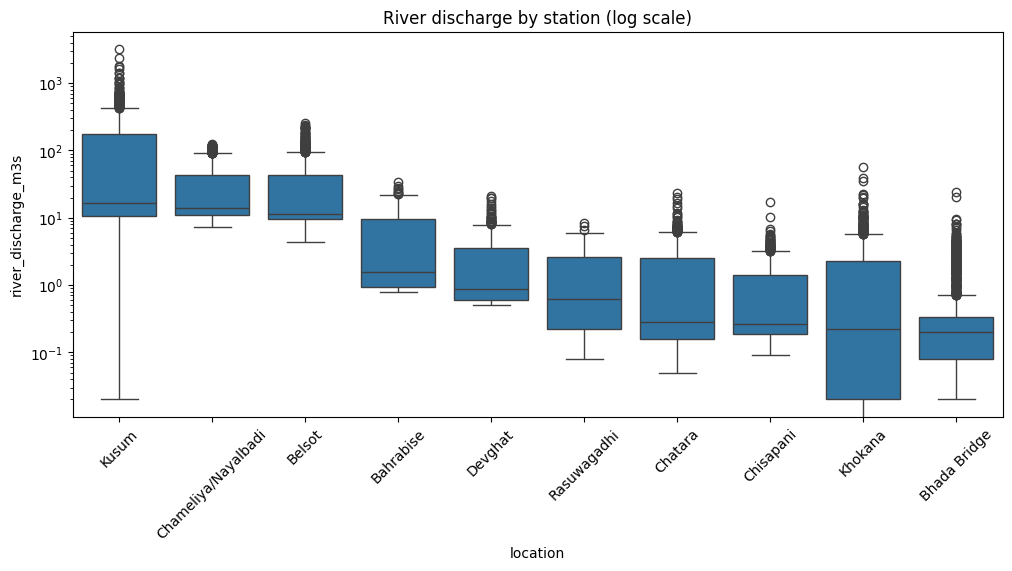

In [ ]:
plt.figure(figsize=(12, 5))
order = df.groupby("location")["river_discharge_m3s"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="location", y="river_discharge_m3s", order=order)
plt.yscale("log"); plt.xticks(rotation=45)
plt.title("River discharge by station (log scale)")
plt.show()

In [ ]:
#9. Analyze the monthly or seasonal pattern of river discharge.

In [ ]:
df['month']=df['date'].dt.month
monthly_discharge=df.groupby('month')['river_discharge_m3s'].mean()
monthly_discharge

,river_discharge_m3s
month,
1,4.309758
2,3.801097
3,3.533565
4,3.200350
5,3.251137
6,6.312908
7,53.719702
8,72.464669
9,52.970000


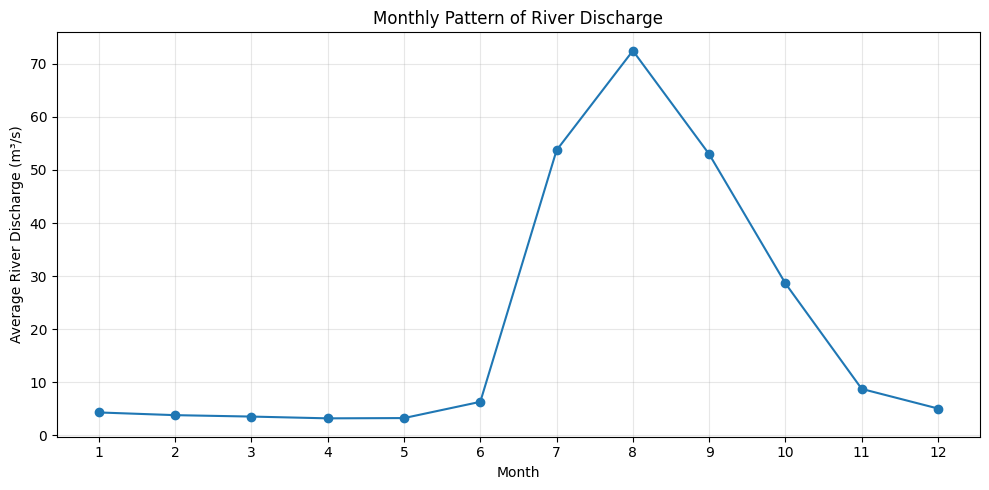

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 13),
    monthly_discharge.values,
    marker="o"
)
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Average River Discharge (m³/s)")
plt.title("Monthly Pattern of River Discharge")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#10. Identify periods with unusually high river discharge.

In [ ]:
df['unusually_high']=df['river_discharge_m3s']>df.groupby('location')['river_discharge_m3s'].transform(lambda x: x.quantile(0.95))


In [ ]:
df.groupby('month')['unusually_high'].sum()

,unusually_high
month,
1,0
2,0
3,0
4,0
5,0
6,7
7,174
8,346
9,88


In [ ]:
df.nlargest(10, "river_discharge_m3s")[["date", "location", "precipitation_mm", "river_discharge_m3s"]]

,date,location,precipitation_mm,river_discharge_m3s
6368,2024-09-28,Kusum,8.4,3175.87
6378,2024-09-29,Kusum,0.9,2359.48
2374,2023-07-04,Kusum,5.6,1802.02
5538,2024-07-07,Kusum,82.0,1736.80
5528,2024-07-06,Kusum,60.9,1609.65
2371,2023-07-01,Kusum,25.8,1421.33
5548,2024-07-08,Kusum,10.2,1418.06
9568,2025-08-14,Kusum,4.9,1190.24
2375,2023-07-05,Kusum,0.8,1182.04
9478,2025-08-05,Kusum,15.2,1173.90


# Feature Engineering

In [ ]:
#11. Create lag features for rainfall, such as previous-day, previous 2-day, and previous 3 day rainfall.

In [ ]:
df=df.sort_values(['location','date']).reset_index(drop=True)

In [ ]:
g=df.groupby('location')

In [ ]:
df.columns

Index(['date', 'location', 'river', 'basin', 'dhm_station', 'latitude',
       'longitude', 'elevation_m', 'precipitation_mm',
       'soil_moisture_0_100cm_m3m3', 'rain_mm', 'temperature_mean_c',
       'dew_point_mean_c', 'precipitation_hours', 'relative_humidity_mean_pct',
       'wind_speed_max_kmh', 'wind_gusts_max_kmh',
       'wind_direction_dominant_deg', 'river_discharge_m3s', 'month',
       'unusually_high'],
      dtype='object')

In [ ]:
df['rain_lag_1']=g['rain_mm'].shift(1)
df['rain_lag_2']=g['rain_mm'].shift(2)
df['rain_lag_3']=g['rain_mm'].shift(3)


In [ ]:
#12. Create rolling rainfall features such as 3-day and 7-day rainfall totals/averages.

In [ ]:
df['rain_sum_3d']=g['rain_mm'].transform(lambda x: x.rolling(3).sum())
df['rain_sum_7d']=g['rain_mm'].transform(lambda x: x.rolling(7).sum())
df['rain_mean_7d']=g['rain_mm'].transform(lambda x: x.rolling(7).mean())

In [ ]:
#13. Create previous-day river discharge features.

In [ ]:
df['river_discharge_lag_1']=g['river_discharge_m3s'].shift(1)
df['river_discharge_lag_2']=g['river_discharge_m3s'].shift(2)
df['river_discharge_mean_7d']=g['river_discharge_m3s'].transform(lambda x: x.rolling(7).mean())


In [ ]:
#14. Extract useful date features such as year and month.

In [ ]:
df["year"]  = df["date"].dt.year                                         # year (2023–2026)
df["month"] = df["date"].dt.month

In [ ]:
#15. Encode the river station/location variable for machine learning.

In [ ]:
loc_dummies = pd.get_dummies(df["location"], prefix="loc", dtype=int)    # one-hot: one 0/1 column per station
df = pd.concat([df, loc_dummies], axis=1)

In [ ]:
df.head()

,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,...,loc_Bahrabise,loc_Belsot,loc_Bhada Bridge,loc_Chameliya/Nayalbadi,loc_Chatara,loc_Chisapani,loc_Devghat,loc_Khokana,loc_Kusum,loc_Rasuwagadhi
0,2023-01-01,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.291,...,1,0,0,0,0,0,0,0,0,0
1,2023-01-02,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.303,...,1,0,0,0,0,0,0,0,0,0
2,2023-01-03,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.306,...,1,0,0,0,0,0,0,0,0,0
3,2023-01-04,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.308,...,1,0,0,0,0,0,0,0,0,0
4,2023-01-05,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.308,...,1,0,0,0,0,0,0,0,0,0


# Machine Learning Prediction

In [ ]:
#16. Create the target variable as the next day's river discharge.

In [ ]:
df['target_next_day']=g['river_discharge_m3s'].shift(-1)

In [ ]:
len(df)

13390

In [ ]:
df_model=df.dropna().reset_index(drop=True)
len(df_model)

13320

In [ ]:
df_model.to_csv("nepal_flood_processed.csv", index=False)

In [ ]:
df_model.columns

Index(['date', 'location', 'river', 'basin', 'dhm_station', 'latitude',
       'longitude', 'elevation_m', 'precipitation_mm',
       'soil_moisture_0_100cm_m3m3', 'rain_mm', 'temperature_mean_c',
       'dew_point_mean_c', 'precipitation_hours', 'relative_humidity_mean_pct',
       'wind_speed_max_kmh', 'wind_gusts_max_kmh',
       'wind_direction_dominant_deg', 'river_discharge_m3s', 'month',
       'unusually_high', 'rain_lag_1', 'rain_lag_2', 'rain_lag_3',
       'rain_sum_3d', 'rain_sum_7d', 'rain_mean_7d', 'river_discharge_lag_1',
       'river_discharge_lag_2', 'river_discharge_mean_7d', 'year',
       'loc_Bahrabise', 'loc_Belsot', 'loc_Bhada Bridge',
       'loc_Chameliya/Nayalbadi', 'loc_Chatara', 'loc_Chisapani',
       'loc_Devghat', 'loc_Khokana', 'loc_Kusum', 'loc_Rasuwagadhi',
       'target_next_day'],
      dtype='object')

In [ ]:
#17. Prepare the input features using weather conditions, historical discharge, date features, and location.

In [ ]:
baseline_features = weather_cols + ["river_discharge_m3s", "latitude", "longitude", "elevation_m"]   # raw columns only
engineered_features = (["rain_lag_1", "rain_lag_2", "rain_lag_3", "rain_sum_3d", "rain_sum_7d", "rain_mean_7d",
                        "river_discharge_lag_1", "river_discharge_lag_2", "river_discharge_mean_7d", "year", "month"]
                       + loc_dummies.columns.tolist())
full_features = baseline_features + engineered_features




In [ ]:
full_features

['precipitation_mm',
 'rain_mm',
 'soil_moisture_0_100cm_m3m3',
 'temperature_mean_c',
 'dew_point_mean_c',
 'precipitation_hours',
 'relative_humidity_mean_pct',
 'wind_speed_max_kmh',
 'wind_gusts_max_kmh',
 'wind_direction_dominant_deg',
 'river_discharge_m3s',
 'latitude',
 'longitude',
 'elevation_m',
 'rain_lag_1',
 'rain_lag_2',
 'rain_lag_3',
 'rain_sum_3d',
 'rain_sum_7d',
 'rain_mean_7d',
 'river_discharge_lag_1',
 'river_discharge_lag_2',
 'river_discharge_mean_7d',
 'year',
 'month',
 'loc_Bahrabise',
 'loc_Belsot',
 'loc_Bhada Bridge',
 'loc_Chameliya/Nayalbadi',
 'loc_Chatara',
 'loc_Chisapani',
 'loc_Devghat',
 'loc_Khokana',
 'loc_Kusum',
 'loc_Rasuwagadhi']

In [ ]:
#18. Split the data into training and testing sets using an appropriate time-based approach.

In [ ]:
dates=np.sort(df_model['date'].unique())
cutoff=dates[int(len(dates)*0.8)]

In [ ]:
train=df_model[df_model['date']<cutoff]
test=df_model[df_model['date']>=cutoff]

In [ ]:
train['date'].min().date(), "to" ,train['date'].max().date()

(datetime.date(2023, 1, 7), 'to', datetime.date(2025, 12, 6))

In [ ]:
test['date'].min().date(), "to" ,test['date'].max().date()

(datetime.date(2025, 12, 7), 'to', datetime.date(2026, 8, 30))

In [ ]:

y_train, y_test = train["target_next_day"], test["target_next_day"]
X_train, X_test = train[full_features], test[full_features]
Xb_train, Xb_test = train[baseline_features], test[baseline_features]

In [ ]:
#20. Train a Linear Regression model

In [ ]:
lr_model=LinearRegression()
lr_model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred_lr=lr_model.predict(X_test)

In [ ]:
print("Predicted discharge:", y_pred_lr[:10])

print("Actual discharge:", y_test.iloc[:10].values)

Predicted discharge: [ 0.31863139 -1.30268832 -0.55063315  0.27651789 -0.39002292 -0.64199993
  0.0892907  -0.12557827  0.05673253  0.57666595]
Actual discharge: [1.7  1.64 1.58 1.52 1.47 1.4  1.36 1.31 1.26 1.23]


In [ ]:
#21. Train a Random Forest Regressor.

In [ ]:
rf_model=RandomForestRegressor(n_estimators=100, random_state=42,n_jobs=-1)
rf_model.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [ ]:
y_pred_rf=rf_model.predict(X_test)

In [ ]:
print("Predicted discharge:", y_pred_rf[:10])

print("Actual discharge:", y_test.iloc[:10].values)

Predicted discharge: [1.7259 1.6278 1.583  1.5561 1.4903 1.4081 1.3637 1.3166 1.2725 1.2253]
Actual discharge: [1.7  1.64 1.58 1.52 1.47 1.4  1.36 1.31 1.26 1.23]


In [ ]:
#22.Gradient Boost

In [ ]:
gb_model=GradientBoostingRegressor(n_estimators=200, random_state=42)
gb_model.fit(X_train, y_train)

GradientBoostingRegressor(n_estimators=200, random_state=42)

In [ ]:
y_pred_gb=gb_model.predict(X_test)

In [ ]:
print("Predicted discharge:", y_pred_gb[:10])

print("Actual discharge:", y_test.iloc[:10].values)

Predicted discharge: [1.6244628  1.35594648 1.35594648 1.35594648 1.35594648 1.12515016
 1.12515016 1.12515016 1.12515016 1.12515016]
Actual discharge: [1.7  1.64 1.58 1.52 1.47 1.4  1.36 1.31 1.26 1.23]


In [ ]:
#Decision Tree

In [ ]:
dt_model=DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [ ]:
y_pred_dt=dt_model.predict(X_test)

In [ ]:
print("Predicted discharge:", y_pred_dt[:10])

print("Actual discharge:", y_test.iloc[:10].values)

Predicted discharge: [1.75 1.69 1.56 1.56 1.53 1.4  1.38 1.32 1.28 1.24]
Actual discharge: [1.7  1.64 1.58 1.52 1.47 1.4  1.36 1.31 1.26 1.23]


In [ ]:
#23. Compare the models using MAE, MSE, RMSE, and R² Score.

In [ ]:
predictions = {
    "Linear Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb,
    "Decision Tree": y_pred_dt
}

results = []

for model_name, y_pred in predictions.items():

    # MAE: Average absolute prediction error
    mae = mean_absolute_error(y_test, y_pred)

    # MSE: Average squared prediction error
    mse = mean_squared_error(y_test, y_pred)

    # RMSE: Square root of MSE
    rmse = np.sqrt(mse)

    # R2: How well the model explains variation in actual discharge
    r2 = r2_score(y_test, y_pred)

    # Store the results
    results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Sort models by RMSE, lowest first
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

# Display the comparison table
display(results_df.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,6.2238,232.1010,15.2349,0.9330
1,Random Forest,2.4271,288.1977,16.9764,0.9168
2,Gradient Boosting,2.9227,382.3576,19.5540,0.8896
3,Decision Tree,3.3718,635.5595,25.2103,0.8164


In [ ]:
#Best model= Random Forest
#Linear Regression has lowest rmse and highest r2_score but Random Forest has lowest MAE and has more accuracy

# Model Evaluation & Interpretation

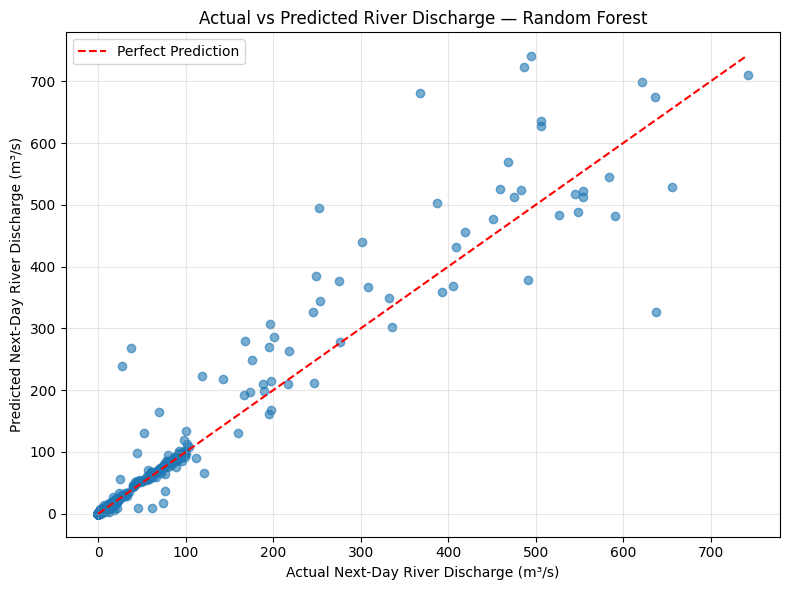

In [ ]:


plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.6
)

min_value = min(np.min(y_test), np.min(y_pred_rf))
max_value = max(np.max(y_test), np.max(y_pred_rf))

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

# Add chart labels and title
plt.xlabel("Actual Next-Day River Discharge (m³/s)")
plt.ylabel("Predicted Next-Day River Discharge (m³/s)")
plt.title("Actual vs Predicted River Discharge — Random Forest")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

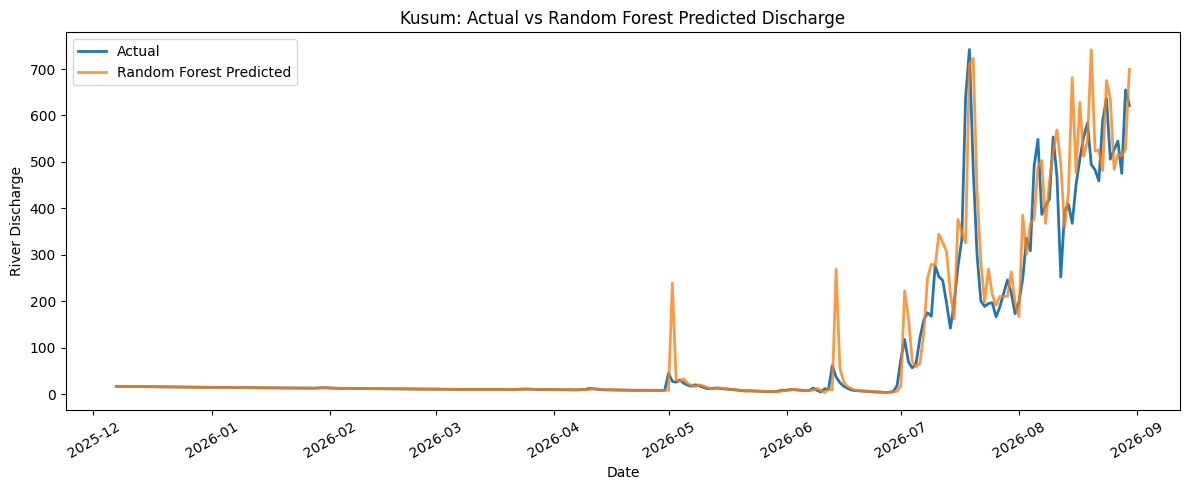

In [ ]:
top_station = avg_discharge.index[0]

mask = (test["location"] == top_station).values

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    test.loc[mask, "date"],
    y_test[mask],
    label="Actual",
    linewidth=2
)

ax.plot(
    test.loc[mask, "date"],
    y_pred_rf[mask],
    label="Random Forest Predicted",
    alpha=0.8,
    linewidth=2
)

ax.set_title(f"{top_station}: Actual vs Random Forest Predicted Discharge")
ax.set_xlabel("Date")
ax.set_ylabel("River Discharge")
ax.legend()
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
#error analysis

In [ ]:
err = test[["date", "location"]].copy()
err['actual']=y_test.values
err['predicted']=y_pred_rf
err['error']=err['actual']-err['predicted']
err['abs_error']=abs(err['error'])

In [ ]:
err.nlargest(10, 'abs_error')

,date,location,actual,predicted,error,abs_error
11972,2026-08-15,Kusum,367.98,681.5047,-313.5247,313.5247
11944,2026-07-18,Kusum,637.26,326.1135,311.1465,311.1465
11977,2026-08-20,Kusum,494.45,741.0541,-246.6041,246.6041
11969,2026-08-12,Kusum,252.51,494.9136,-242.4036,242.4036
11946,2026-07-20,Kusum,486.53,723.4151,-236.8851,236.8851
11910,2026-06-14,Kusum,37.11,269.0810,-231.9710,231.9710
11867,2026-05-02,Kusum,27.84,238.8654,-211.0254,211.0254
11947,2026-07-21,Kusum,301.69,440.3241,-138.6341,138.6341
11959,2026-08-02,Kusum,249.03,385.5367,-136.5067,136.5067
11982,2026-08-25,Kusum,505.99,635.6958,-129.7058,129.7058


In [ ]:
#28. Identify the most important features affecting river discharge prediction.

In [ ]:

imp = pd.Series(
    rf_model.feature_importances_,
    index=full_features
).sort_values(ascending=False)


print("Top 10 Features Affecting River Discharge Prediction:")
print(imp.head(10).round(4))



Top 10 Features Affecting River Discharge Prediction:
river_discharge_m3s           0.8025
rain_sum_3d                   0.0626
temperature_mean_c            0.0265
precipitation_mm              0.0181
rain_mm                       0.0152
soil_moisture_0_100cm_m3m3    0.0096
dew_point_mean_c              0.0085
precipitation_hours           0.0082
river_discharge_lag_1         0.0069
wind_speed_max_kmh            0.0067
dtype: float64


In [ ]:
#29. Create a feature importance visualization for the best model.

<Axes: >

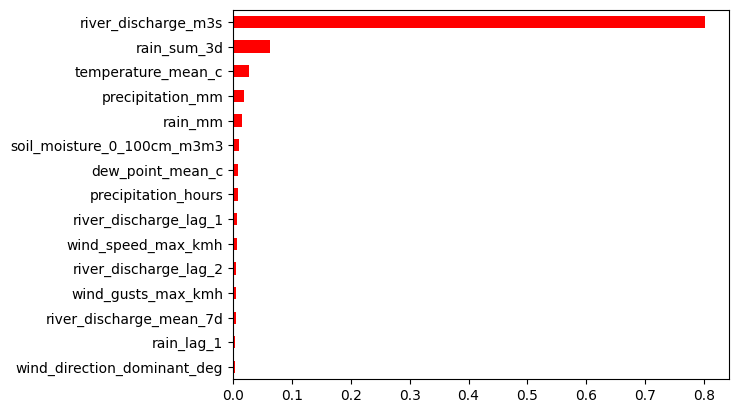

In [ ]:

top_15 = imp.head(15).sort_values(ascending=True)
top_15.plot(kind='barh',color='red')

In [ ]:
#Advanced / Bonus Task – High-Flow Classification

In [ ]:
#31. Create a High Flow = 1 and Normal Flow = 0 target.

In [ ]:
thresholds = train.groupby("location")["river_discharge_m3s"].quantile(0.90)
print("High-flow thresholds (m³/s):\n", thresholds.round(2))

train_thr = train["location"].map(thresholds)
test_thr  = test["location"].map(thresholds)
yc_train = (train["target_next_day"] > train_thr).astype(int)
yc_test  = (test["target_next_day"]  > test_thr).astype(int)

High-flow thresholds (m³/s):
 location
Bahrabise               13.68
Belsot                  94.63
Bhada Bridge             2.66
Chameliya/Nayalbadi     92.24
Chatara                  4.57
Chisapani                2.63
Devghat                  6.29
Khokana                  4.99
Kusum                  426.96
Rasuwagadhi              3.59
Name: river_discharge_m3s, dtype: float64


In [ ]:
#32. Handle any class imbalance appropriately.

In [ ]:
print("\nClass balance (train):\n", yc_train.value_counts(normalize=True).round(3))
print("Class balance (test):\n",  yc_test.value_counts(normalize=True).round(3))
print("-> High flow is rare, so we use class_weight='balanced' (gives the rare class more importance).")


Class balance (train):
 0    0.9
1    0.1
Name: proportion, dtype: float64
Class balance (test):
 0    0.936
1    0.064
Name: proportion, dtype: float64
-> High flow is rare, so we use class_weight='balanced' (gives the rare class more importance).


In [ ]:
#33. Train Logistic Regression, Decision Tree, and Random Forest classification models.

In [ ]:
clf_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Decision Tree":       DecisionTreeClassifier(class_weight="balanced", max_depth=6, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1),
}
clf_results, clf_preds = {}, {}
for name, clf in clf_models.items():
    clf.fit(X_train, yc_train)
    p = clf.predict(X_test)
    clf_preds[name] = p
    clf_results[name] = {"Accuracy":  accuracy_score(yc_test, p),
                         "Precision": precision_score(yc_test, p, zero_division=0),
                         "Recall":    recall_score(yc_test, p, zero_division=0),
                         "F1":        f1_score(yc_test, p, zero_division=0)}
clf_df = pd.DataFrame(clf_results).T.round(3)

display(clf_df)

,Accuracy,Precision,Recall,F1
Logistic Regression,0.840,0.288,1.000,0.447
Decision Tree,0.873,0.335,0.983,0.500
Random Forest,0.967,0.744,0.744,0.744


In [ ]:
#34. Evaluate the models using Accuracy, Precision, Recall, F1-score, and a Confusion Matrix.

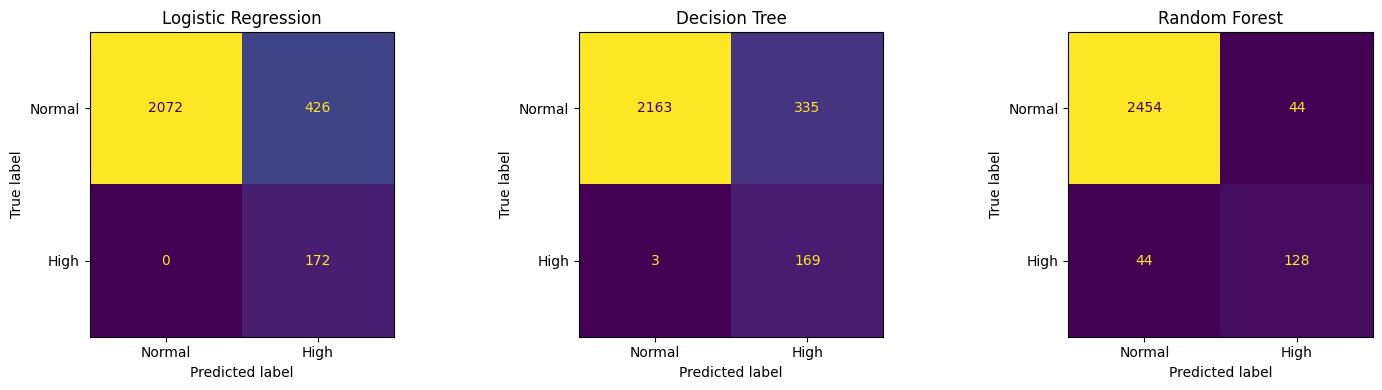

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, p) in zip(ax, clf_preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(yc_test, p), display_labels=["Normal", "High"]).plot(ax=a, colorbar=False)
    a.set_title(name)
plt.tight_layout()
plt.show()

In [ ]:
#35. Identify the best classification model.

In [ ]:
best_clf_name = clf_df["F1"].idxmax()
best_clf_name

'Random Forest'

In [ ]:
#36. Explain which features contribute most to high-flow prediction.

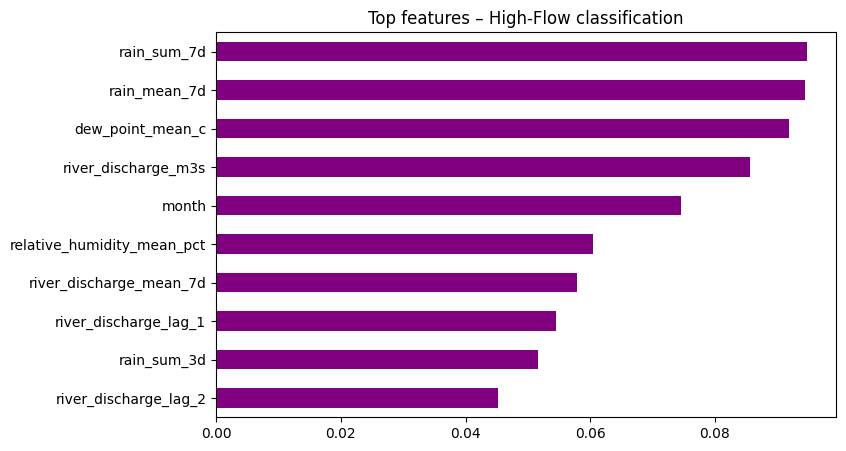

In [ ]:
rf_clf = clf_models["Random Forest"]
clf_imp = pd.Series(rf_clf.feature_importances_, index=full_features).sort_values(ascending=False)
clf_imp.head(10).sort_values().plot(kind="barh", color="purple", title="Top features – High-Flow classification", figsize=(8, 5))
plt.show()

In [ ]:
clf_imp.head(10)

,0
rain_sum_7d,0.094698
rain_mean_7d,0.094382
dew_point_mean_c,0.091955
river_discharge_m3s,0.085571
month,0.074604
relative_humidity_mean_pct,0.060496
river_discharge_mean_7d,0.057898
river_discharge_lag_1,0.054592
rain_sum_3d,0.051606
river_discharge_lag_2,0.045255
